# Function 8 - Week 10: Observation review

Review the round 9 return received on **25 November 2026 at 12:51 GMT**. The official snapshot contains **40 starting observations and nine returns (49 rows)** across 8 input coordinates.

The latest signed output is **9.87426736787**, ranked **3/49**. Four queries remain per function, including Week 10.

Continue in [model predictions](model_predictions.ipynb) and the [week-level report](report.md).

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "exploration_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's own week folder.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))
from exploration_review_helpers import load_exploration_review
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_input_profiles,
    plot_output_review, plot_round_progress,
)
from query_budget import remaining_queries

print("Python:", sys.executable)

from observation_review_helpers import replay_weekly_forecast

Python: C:\_Source\Imperial-ML-AI-Live\Capstone\imperial-capstone\.venv\Scripts\python.exe


In [2]:
FUNCTION_NUMBER = 8
CURRENT_WEEK = 10
INPUT_COLUMNS = ['x1', 'x2', 'x3', 'x4', 'x5', 'x6', 'x7', 'x8']
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 40, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1, 9: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent if ANALYSIS_DIR.name == "official" else ANALYSIS_DIR
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"


In [3]:
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
prepared = prepare_weekly_observation_review(review)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))
print(review["report"])


,observation_id,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y,output_rank
48,round-09,9,0.0,0.365002,0.020186,0.15,0.796758,0.436941,0.101883,0.630634,9.874267,3


Latest recorded submission: round 9 (1 new output).
Compared with 48 earlier observations (49 outputs in total).
Earlier output range: [5.59219338954, 9.93677342466].

round-09: y = 9.87426736787 (positive); rank 3/49 (1 = highest output).
Inputs: x1 = 0, x2 = 0.365002, x3 = 0.020186, x4 = 0.15, x5 = 0.796758, x6 = 0.436941, x7 = 0.101883, x8 = 0.630634
Within the earlier output range.


### Measured outputs

Both panels use signed outputs in their original units. The close-up shows only the highest five; all observations remain in the full-range panel and calculations.

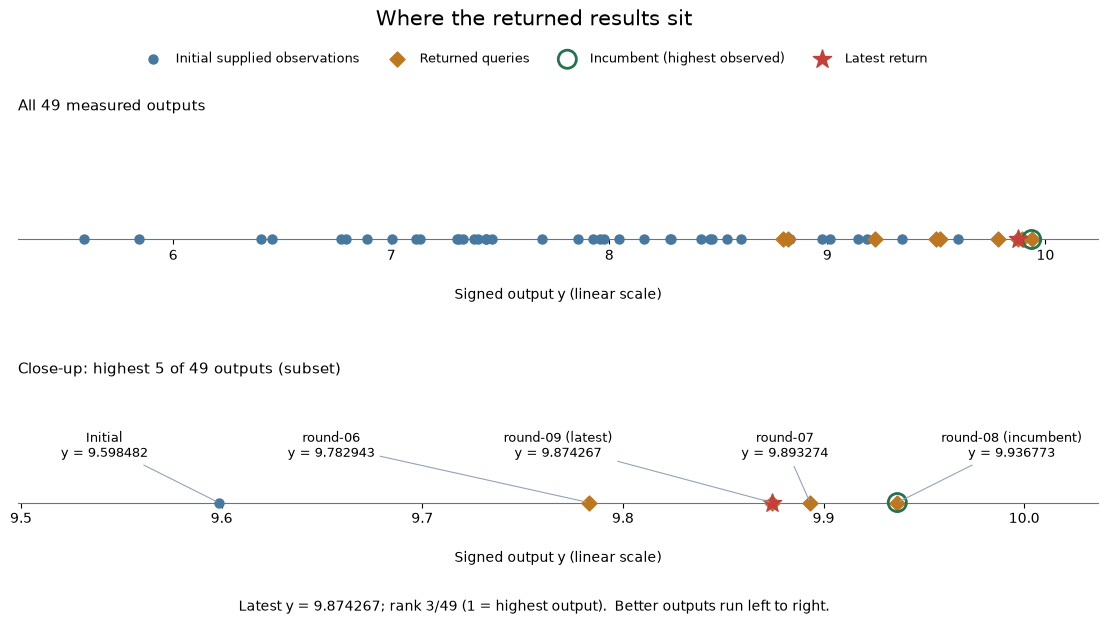

In [4]:
plot_output_review(review, save_to=FIGURES_DIR / "observed-output-review.png")

### Progress across completed rounds

The initial rows form one starting batch. Compare each return with the best known before that round.

In [5]:
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]]
    .rename(columns={"returned_y": "Returned output", "best_y": "Best observed after stage",
                     "change_vs_prior_best": "Return minus previous best"})
    .style.format(precision=6, na_rep="Not applicable"))


,Returned output,Best observed after stage,Return minus previous best
stage,,,
Initial batch,Not applicable,9.598482,Not applicable
Round 1,9.498300,9.598482,-0.100182
Round 2,9.518300,9.598482,-0.080182
Round 3,8.798303,9.598482,-0.800179
Round 4,8.818303,9.598482,-0.780179
Round 5,9.218300,9.598482,-0.380182
Round 6,9.782943,9.782943,0.184461
Round 7,9.893274,9.893274,0.110331
Round 8,9.936773,9.936773,0.043500


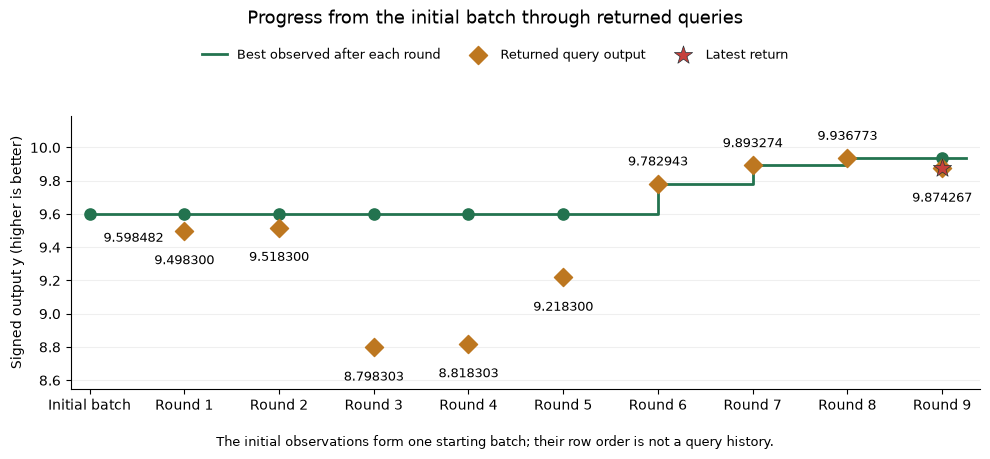

In [6]:
plot_round_progress(prepared["progress"], save_to=FIGURES_DIR / "observed-progress.png")

### Strongest measured input combinations

Keep all 8 coordinates visible. Colour shows input settings on a common 0–1 scale; it does not encode performance or input effects. Use the table for six-decimal settings.

,rank,source_round,x1,x2,x3,x4,x5,x6,x7,x8,y
observation_id,,,,,,,,,,,
round-08,1,8,0.042902,0.215002,0.170186,0.000000,0.946758,0.586941,0.251883,0.480634,9.936773
round-07,2,7,0.000000,0.126300,0.212455,0.132451,0.899004,0.732961,0.231231,0.808273,9.893274
round-09,3,9,0.000000,0.365002,0.020186,0.150000,0.796758,0.436941,0.101883,0.630634,9.874267
round-06,4,6,0.022327,0.096114,0.237034,0.202848,0.982361,0.880106,0.159960,0.678158,9.782943
initial-015,5,0,0.056447,0.065956,0.022929,0.038786,0.403935,0.801055,0.488307,0.893085,9.598482


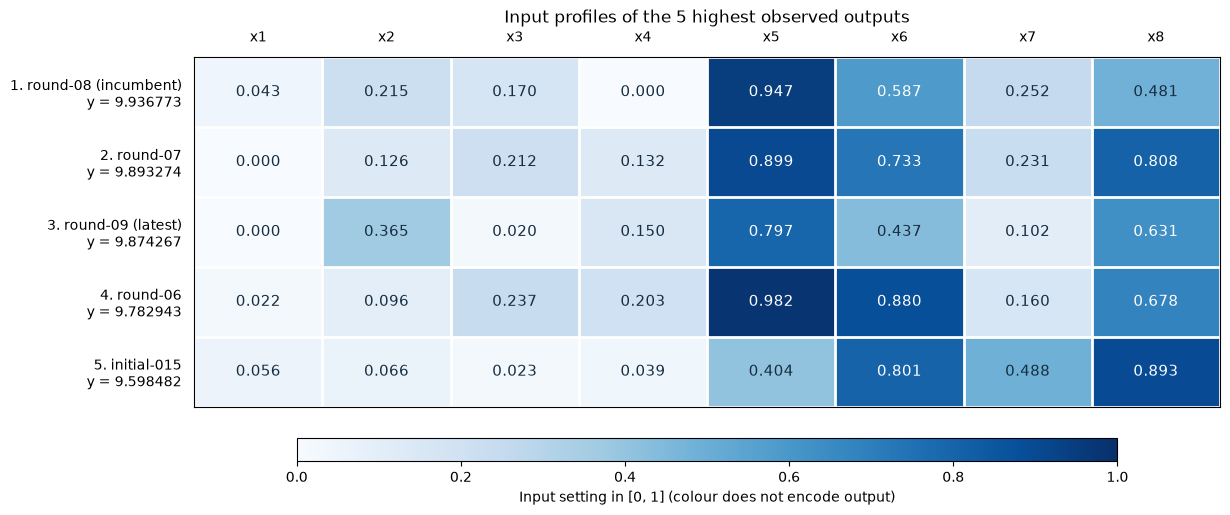

In [7]:
display(prepared["strongest"][["rank", "observation_id", "source_round", *INPUT_COLUMNS, OUTPUT_COLUMN]]
    .set_index("observation_id").style.format({column: "{:.6f}" for column in [*INPUT_COLUMNS, OUTPUT_COLUMN]}))
plot_input_profiles(
    prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=prepared["latest"]["observation_id"], incumbent_id=prepared["incumbent"]["observation_id"],
    save_to=FIGURES_DIR / "strongest-input-profiles.png",
)


### Latest input versus earlier evidence

Distances use every input coordinate. Similar input settings do not guarantee similar outputs or isolate the effect of one coordinate.

In [8]:
display(prepared["coordinate_changes"].style.format(precision=6))
display(pd.Series(prepared["neighbour_summary"]))


,Previous best,Latest query,Latest minus previous best
x1,0.042902,0.000000,-0.042902
x2,0.215002,0.365002,0.150000
x3,0.170186,0.020186,-0.150000
x4,0.000000,0.150000,0.150000
x5,0.946758,0.796758,-0.150000
x6,0.586941,0.436941,-0.150000
x7,0.251883,0.101883,-0.150000
x8,0.480634,0.630634,0.150000


previous_best_id              round-08
previous_best_output          9.936773
distance_to_previous_best     0.399175
latest_minus_previous_best   -0.062506
nearest_previous_id           round-08
nearest_previous_distance     0.399175
dtype: object

### Replay the archived Week 9 fits at the submitted input

The exported weekly fits predate round 9. Evaluate them at the exact submitted coordinates. Some final choices used different decision models and broader peer evidence. GP latent SD describes modelled uncertainty about the latent score. Neural seed SD describes variation between the three training seeds.

In [9]:
# Replay the frozen Week 9 weekly fits at the actual submitted coordinates.
stage_dir = shared_dir.parent.parent
feedback = json.loads((stage_dir / "submissions/round-09-results.json").read_text(encoding="utf-8"))
submission_path = stage_dir / feedback["proposals_source"]
if (feedback["round"] != CURRENT_WEEK - 1
        or hashlib.sha256(submission_path.read_bytes()).hexdigest() != feedback["proposals_sha256"]):
    raise ValueError("Archived submission does not match the round result.")
actual_point = prepared["latest"][INPUT_COLUMNS].to_numpy(dtype=float)
actual_output = float(prepared["latest"][OUTPUT_COLUMN])
result = feedback["results"][FUNCTION_NUMBER - 1]
portal_input = "-".join(f"{value:.6f}" for value in actual_point)
if (result["function"] != FUNCTION_NUMBER or not result["matches_proposal"]
        or result["point"] != actual_point.tolist() or result["output"] != actual_output
        or result["observations"] != len(review["data"])
        or portal_input != result["portal_input"]
        or portal_input != submission_path.read_text(encoding="utf-8").splitlines()[FUNCTION_NUMBER - 1]):
    raise ValueError("Official observation does not match the submitted and returned evaluation.")
previous_week = WEEK_DIR.parent / f"Week_{CURRENT_WEEK - 1:02d}"
previous_analysis = previous_week / "official" if ANALYSIS_DIR.name == "official" else previous_week
historical_forecast = replay_weekly_forecast(previous_analysis, function=FUNCTION_NUMBER,
    week=CURRENT_WEEK - 1, input_columns=INPUT_COLUMNS, point=actual_point)
scale = historical_forecast["height_scale"]
actual_target = float(signed_log(actual_output, scale=scale)) if scale is not None else actual_output
historical_forecast.update(
    source=(previous_analysis / "figures/neural-network-explorer.html").relative_to(stage_dir).as_posix(),
    portal_input=portal_input, actual_output=actual_output, actual_in_prediction_units=actual_target,
    actual_minus_gp_mean=actual_target - historical_forecast["gp_mean"],
    actual_minus_neural_mean=actual_target - historical_forecast["neural_mean"],
)
display(pd.Series(historical_forecast).drop(["official_snapshot_sha256", "explorer_sha256"]))


gp_model                                                       Gaussian process
data_scope                                                             official
prediction_units                                                       output y
height_scale                                                               None
gp_mean                                                                9.996644
gp_latent_sd                                                           0.191627
neural_architecture                                                     tanh-16
neural_mean                                                            9.520305
neural_seed_sd                                                         0.017406
source                        notebooks/Function_8/Week_09/figures/neural-ne...
portal_input                  0.000000-0.365002-0.020186-0.150000-0.796758-0...
actual_output                                                          9.874267
actual_in_prediction_units              

### What the return adds

The Matérn query scored 9.87426737, about 0.06251 below the official best. The newly measured point and incumbent differ across the eight-dimensional profile.

In [10]:
# Full-precision review record; tiny signed outputs are never rounded to zero.
observation_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(review["data"]),
    "latest_id": prepared["latest"]["observation_id"],
    "latest_output": float(prepared["latest"][OUTPUT_COLUMN]),
    "latest_rank": int(review["latest_submissions"].iloc[0]["output_rank"]),
    "rank_definition": "1 = highest output",
    "best_id": prepared["incumbent"]["observation_id"],
    "best_observed_output": float(prepared["incumbent"][OUTPUT_COLUMN]),
    "positive_outputs": int((review["outputs"] > 0).sum()),
    "negative_outputs": int((review["outputs"] < 0).sum()),
    "exact_zeros": int((review["outputs"] == 0).sum()),
    "progress": prepared["progress"].fillna("not_applicable").to_dict(orient="records"),
    "official_history_comparison": prepared["neighbour_summary"],
    "historical_forecast": historical_forecast,
    "remaining_queries": remaining_queries(WEEK_DIR),
}
(ANALYSIS_DIR / "observation-review.json").write_text(
    json.dumps(observation_summary, indent=2, allow_nan=False) + "\n", encoding="utf-8")
print(json.dumps(observation_summary, indent=2))


{
  "function": 8,
  "week": 10,
  "observations": 49,
  "latest_id": "round-09",
  "latest_output": 9.8742673678714,
  "latest_rank": 3,
  "rank_definition": "1 = highest output",
  "best_id": "round-08",
  "best_observed_output": 9.9367734246634,
  "positive_outputs": 49,
  "negative_outputs": 0,
  "exact_zeros": 0,
  "progress": [
    {
      "source_round": 0,
      "stage": "Initial batch",
      "returned_y": "not_applicable",
      "best_y": 9.598482002566342,
      "change_vs_prior_best": "not_applicable"
    },
    {
      "source_round": 1,
      "stage": "Round 1",
      "returned_y": 9.4983001999995,
      "best_y": 9.598482002566342,
      "change_vs_prior_best": -0.10018180256684239
    },
    {
      "source_round": 2,
      "stage": "Round 2",
      "returned_y": 9.5183002799994,
      "best_y": 9.598482002566342,
      "change_vs_prior_best": -0.08018172256694278
    },
    {
      "source_round": 3,
      "stage": "Round 3",
      "returned_y": 8.7983028999975,
      

### Course lifecycle for this review

1. **Define the goal and scope** — review round 9 for the project owner and prepare descriptive evidence for the Week 10 decision.
2. **Gather the data** — use the 25 November result, the independent official snapshot and the archived Week 9 weekly fits.
3. **Explore the data** — inspect measured ranks, progress and sampling coverage or full input profiles.
4. **Clean and preprocess the data** — validate finite values, dimensions, bounds and round counts at full precision.
5. **Select and engineer features** — keep the ordered input coordinates. Additional features are unnecessary for the measured views.
6. **Define the machine-learning task** — this review describes observations for a continuous black-box maximisation task.
7. **Partition the data** — not applicable to this descriptive review. The comparison uses fits already frozen before round 9.
8. **Select and train candidate methods** — not applicable to this review. The model notebook fits and compares the candidates.
9. **Evaluate and interpret the results** — compare the latest measured value with the incumbent, earlier outputs and the archived fits at the submitted coordinates.
10. **Deploy and iterate** — deployment is not applicable to this review. Carry the evidence into the next query decision.
